## CMPSC 105 Lab 07: Interpreting Hypothesis Tests

Your name(s): Rafael Leme

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# 1. DATA GENERATION (Run this cell to load your "lab_data")

# Generate doomscolling data
n_users = 1000

user_baselines = np.random.gamma(shape=3.0, scale=40.0, size=n_users)
standard_time = user_baselines + np.random.normal(loc=0, scale=10, size=n_users)
new_time = user_baselines + np.random.normal(loc=1.5, scale=10, size=n_users)
df_doomscrolling = pd.DataFrame({
    'user_id': np.arange(n_users),
    'standard_time': standard_time,
    'new_time': new_time
})
df_doomscrolling['difference'] = df_doomscrolling['new_time'] - df_doomscrolling['standard_time']
df_doomscrolling = df_doomscrolling.sample(frac=1, ignore_index=True)
    

# Generate e-commerce A/B test Data
blue_spending = np.random.normal(loc=42.50, scale=25.0, size=2000)
green_spending = np.random.normal(loc=43.10, scale=25.0, size=2000)
blue_spending = np.clip(blue_spending, a_min=0, a_max=None)
green_spending = np.clip(green_spending, a_min=0, a_max=None)

df_ecommerce = pd.DataFrame({
    'button_color': ['Blue'] * 2000 + ['Green'] * 2000,
    'spending': np.concatenate([blue_spending, green_spending])
})
df_ecommerce = df_ecommerce.sample(frac=1, ignore_index=True)

print("Datasets generated successfully!")


Datasets generated successfully!


### Scenario 1: The E-Commerce A/B Test

An e-commerce company is conducting an **A/B test** to determine the effect of button color on user spending for their shopping app. An A/B test is a controlled experiment where two or more variants of a single variable are compared to determine which performs better. In this case, the variable is the button color, and the outcome is user spending. 

Users are randomly assigned to see either a blue or green button, and their spending is recorded. The goal is to assess whether the button color influences the amount users spend.

In [4]:
df_ecommerce.head()

,button_color,spending
0,Green,11.251652
1,Green,65.276997
2,Green,3.481732
3,Green,77.342378
4,Green,47.517303


In [5]:
# Calculate the observed difference in means
ecomm_means = df_ecommerce.groupby('button_color')['spending'].mean()
obs_diff_ecomm = ecomm_means['Green'] - ecomm_means['Blue']

print(f"Blue Button Mean: ${ecomm_means['Blue']:.2f}")
print(f"Green Button Mean: ${ecomm_means['Green']:.2f}")
print(f"Observed Difference: ${obs_diff_ecomm:.2f}")


Blue Button Mean: $42.34
Green Button Mean: $44.04
Observed Difference: $1.70


We can test whether the differenece between the green and blue button spending is statistically significant using a permutation test, where we repeatedly shuffle the button color labels and calculate the difference in mean spending between the green and blue buttons. This generates a null distribution of differences, which we can then compare to the observed difference to compute a p-value.

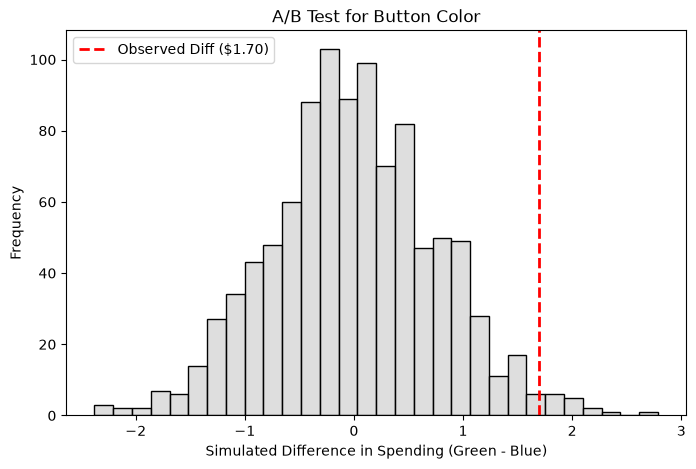

P-value for A/B Test (Button Color): 0.9840


In [6]:
# Permutation test
n_iter = 1000
simulated_diffs_ecomm = np.zeros(n_iter)

spending_vals = df_ecommerce['spending'].values
color_labels = df_ecommerce['button_color'].values

for i in range(n_iter):
    # Shuffle the labels
    shuffled = np.random.permutation(color_labels)
    
    # Calculate simulated means
    green_mean = spending_vals[shuffled == 'Green'].mean()
    blue_mean = spending_vals[shuffled == 'Blue'].mean()
    
    # Store the difference
    simulated_diffs_ecomm[i] = green_mean - blue_mean

plt.figure(figsize=(8, 5))
sns.histplot(simulated_diffs_ecomm, bins=30, color='lightgray', edgecolor='black')
plt.axvline(obs_diff_ecomm, color='red', linestyle='dashed', linewidth=2, label=f'Observed Diff (${obs_diff_ecomm:.2f})')
plt.title('A/B Test for Button Color')
plt.xlabel('Simulated Difference in Spending (Green - Blue)')
plt.ylabel('Frequency')
plt.legend()
plt.show()

p_value_ecomm = (simulated_diffs_ecomm <= obs_diff_ecomm).mean()
print(f"P-value for A/B Test (Button Color): {p_value_ecomm:.4f}")

Write a one-paragraph summary of the results of the A/B test for button color, including the observed difference, the simulated distribution, and the p-value. What is the hypothesis test testing? Based on the information, would you recommend using the green button or the blue button?

The A/B test for button color showed that the green button had a spending average of $44.04, while the blue had $42.34, an observed difference of $1.70. The simulated distribution was mostly concentrated near 0, and the shown p value was 0.9840. Because this value is higher than 0.05, the hyphothesis of the buttons not influencing the spending amount is still possible. Overrall, based on the shown p value, there's not sufficient evidence to reccomend the green button instead of the blue one.

### Scenario 2: Doomscrolling Algorithms

A major social media company (think TikTok or Instagram) has developed a new, highly complex deep-learning algorithm for their video feed. The engineering team claims it is more effective with users and will increase daily screen time. To test it, they roll out the new algorithm to 1,000 users. Each user spends one week on the Standard feed, and one week on the New feed. The Metric: Average daily screen time per user (in minutes).

In [7]:
df_doomscrolling.head()

,user_id,standard_time,new_time,difference
0,114,68.971498,63.431101,-5.540397
1,104,97.970305,89.209319,-8.760986
2,370,107.169678,126.539686,19.370008
3,402,109.104019,143.990975,34.886956
4,670,101.127612,92.017279,-9.110333


In [8]:
# Calculate the observed difference in means
print(f'Standard Algorithm Mean: {df_doomscrolling["standard_time"].mean()}')
print(f'New Algorithm Mean: {df_doomscrolling["new_time"].mean()}')
print(f'Observed Difference: {df_doomscrolling["difference"].mean()}')

Standard Algorithm Mean: 118.13694180740895
New Algorithm Mean: 119.06510026899493
Observed Difference: 0.9281584615859769


We can test whether the difference between the standard and new algorithm times is statistically significant using a permutation test. Since the difference is calculated for each user, we cannot just swap labels. Instead, we swap the `standard_time` and `new_time` values for randomly selected rows (thereby flipping the sign of `difference`).

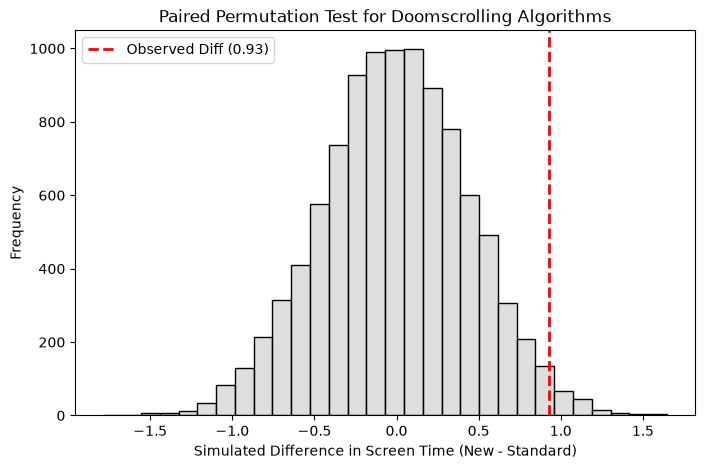

P-value for Paired Permutation Test (Doomscrolling Algorithms): 0.0375


In [9]:
# paired permutation test
def paired_permutation_test(df, col1, col2, n_permutations=10000):
    observed_difference = df[col2] - df[col1]
    observed_stat = observed_difference.mean()
    null_distribution = []
    for _ in range(n_permutations):
        permuted_difference = observed_difference.copy()
        flip = np.random.choice([True, False], size=len(permuted_difference))
        permuted_difference[flip] = -permuted_difference[flip]
        null_distribution.append(permuted_difference.mean())
    null_distribution = np.array(null_distribution)
    p_value = (np.abs(null_distribution) >= np.abs(observed_stat)).mean()
    return observed_stat, p_value, null_distribution

obs_diff, p_value, null_dist = paired_permutation_test(df_doomscrolling, 'standard_time', 'new_time', n_permutations=10000)

plt.figure(figsize=(8, 5))
sns.histplot(null_dist, bins=30, color='lightgray', edgecolor='black')
plt.axvline(obs_diff, color='red', linestyle='dashed', linewidth=2, label=f'Observed Diff ({obs_diff:.2f})')
plt.title('Paired Permutation Test for Doomscrolling Algorithms')
plt.xlabel('Simulated Difference in Screen Time (New - Standard)')
plt.ylabel('Frequency')
plt.legend()
plt.show()

print(f"P-value for Paired Permutation Test (Doomscrolling Algorithms): {p_value:.4f}")

Write a one-paragraph summary of the results for the doomscrolling algorithms. Include the observed difference, the p-value, and a conclusion on whether the new algorithm significantly increases screen time. Be sure to include what the hypothesis test is testing.

The hypothesis test examines whether the new algorithm significantly increases daily screen time on social media compared to the standard algorithm. The observed difference was approximately 0.93 minutes, showing that users spent slightly more time using the new algorithm. The simulated distribution was concentrated around zero, and the p-value was 0.0375. Since this value is less than 0.05, we can reject the null hypothesis and conclude that the new algorithm significantly increases users' daily screen time. However, even though the result is statistically significant, the actual increase is relatively small.